
# ROLL NUMBER: M26AI1124

# Foundations of Vision and Language — Individual Mini CV Project (20 Marks)

# 10 Marks for coding and 10 marks for analysis

## Effect of Blur and Sharpening on Object Detection

- **Dataset:** COCO128
- **Model:** Pretrained YOLO11n
- **Platform:** Google Colab
- **Training:** Not required

### What this notebook provides
- package installation,
- COCO128 download,
- pretrained YOLO11n loading,
- dataset paths.

### What you must do
1. **Stage 1 — Baseline:** evaluate YOLO11n on the original COCO128 images.
2. **Stage 2 — Blur:** create a Gaussian-blurred version of the same images and evaluate again.
3. **Stage 3 — Sharpening:** sharpen the blurred images and evaluate again.
4. **Stage 4 — Analysis:** compare the three stages.

The experimental code for Stages 1–3 is intentionally left for you to complete.


## Setup 1 — Install Packages

In [13]:
!pip -q install -U ultralytics pyyaml


[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


## Setup 2 — Download COCO128

In [14]:
from pathlib import Path
import urllib.request
import zipfile
import os

CWD = Path(os.getcwd())
DATA_ROOT = CWD / 'datasets'
DATA_ROOT.mkdir(parents=True, exist_ok=True)

zip_path = DATA_ROOT / 'coco128.zip'
dataset_dir = DATA_ROOT / 'coco128'

if not dataset_dir.exists():
    url = 'https://github.com/ultralytics/assets/releases/download/v0.0.0/coco128.zip'
    print('Downloading COCO128 to:', zip_path)
    urllib.request.urlretrieve(url, zip_path)
    with zipfile.ZipFile(zip_path, 'r') as zf:
        zf.extractall(DATA_ROOT)
    print('Download and extraction complete.')
else:
    print('COCO128 already exists.')

print('Dataset ready at:', dataset_dir)

IMG_DIR = dataset_dir / 'images' / 'train2017'
LBL_DIR = dataset_dir / 'labels' / 'train2017'
print('Images:', IMG_DIR)
print('Labels:', LBL_DIR)

Download and extraction complete.
Dataset ready at: d:\projects\iitj_foundation_repo\CV assignment\datasets\coco128
Images: d:\projects\iitj_foundation_repo\CV assignment\datasets\coco128\images\train2017
Labels: d:\projects\iitj_foundation_repo\CV assignment\datasets\coco128\labels\train2017


## Setup 3 — Load Pretrained YOLO11n

In [15]:
PROJECT_ROOT = CWD / 'fvl_project'
PROJECT_ROOT.mkdir(parents=True, exist_ok=True)

from ultralytics import YOLO
model = YOLO('yolo11n.pt')
print('Project folder:', PROJECT_ROOT)
print('Model loaded')

Project folder: d:\projects\iitj_foundation_repo\CV assignment\fvl_project
Model loaded



# Stage 1 — Baseline on Original Images

### Your task
1. Prepare a dataset YAML that points to the original COCO128 images and labels.
2. Run `model.val(...)` using the pretrained YOLO11n model.
3. Record only these four metrics:
   - Precision
   - Recall
   - mAP@0.5
   - mAP@0.5:0.95
4. Save at least **3 prediction examples**.


In [16]:
import yaml

baseline_yaml = {
    'path': str(dataset_dir),
    'train': 'images/train2017',
    'val': 'images/train2017',
    'names': {i: name for i, name in enumerate(model.names.values())}
}

yaml_path = PROJECT_ROOT / 'baseline.yaml'
with open(yaml_path, 'w') as f:
    yaml.dump(baseline_yaml, f)

results_baseline = model.val(data=str(yaml_path), project=str(PROJECT_ROOT), name='baseline', exist_ok=True)

print('Precision:', round(results_baseline.results_dict['metrics/precision(B)'], 4))
print('Recall:', round(results_baseline.results_dict['metrics/recall(B)'], 4))
print('mAP@0.5:', round(results_baseline.results_dict['metrics/mAP50(B)'], 4))
print('mAP@0.5:0.95:', round(results_baseline.results_dict['metrics/mAP50-95(B)'], 4))

Ultralytics 8.4.189  Python-3.13.3 torch-2.6.0+cu124 CUDA:0 (NVIDIA GeForce RTX 3080, 10240MiB)
YOLO11n summary (fused): 100 layers, 2,616,248 parameters, 0 gradients, 6.5 GFLOPs
WARNING val: Slow image access detected (ping: 0.0±0.0 ms, read: 9.6±4.0 MB/s, size: 44.9 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning D:\projects\iitj_foundation_repo\CV assignment\datasets\coco128\labels\train2017... 126 images, 2 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 128/128 1.4Kit/s 0.1s
val: New cache created: D:\projects\iitj_foundation_repo\CV assignment\datasets\coco128\labels\train2017.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 1.8s/it 14.4s0.3s6
                   all        128        929      0.663      0.589      0.671      0.503
                person         61        254      0.799      0.687      0.788      


0: 640x640 9 birds, 4.0ms
1: 640x640 8 persons, 2 horses, 1 potted plant, 4.0ms
2: 640x640 6 persons, 4.0ms
Speed: 1.8ms preprocess, 4.0ms inference, 1.2ms postprocess per image at shape (1, 3, 640, 640)
Results saved to D:\projects\iitj_foundation_repo\CV assignment\fvl_project\baseline_preds
000000000143.jpg: bird 0.85, bird 0.82, bird 0.82, bird 0.72, bird 0.59, bird 0.51, bird 0.42, bird 0.38, bird 0.34
000000000049.jpg: horse 0.75, potted plant 0.72, horse 0.7, person 0.57, person 0.52, person 0.4, person 0.33, person 0.3, person 0.29, person 0.28, person 0.26
000000000395.jpg: person 0.93, person 0.86, person 0.83, person 0.53, person 0.3, person 0.26


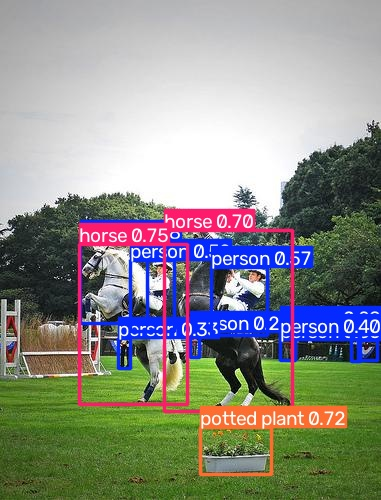

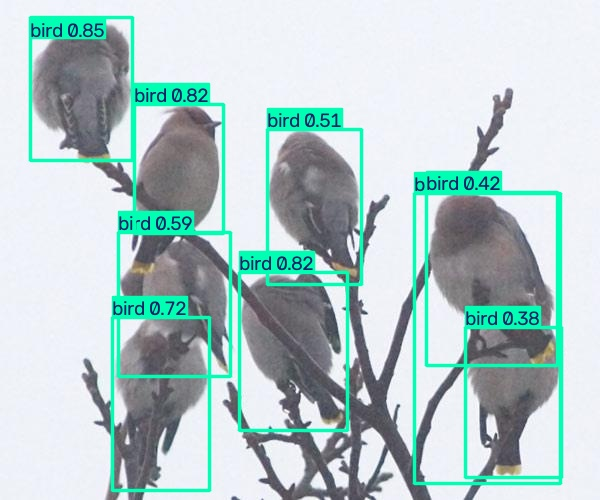

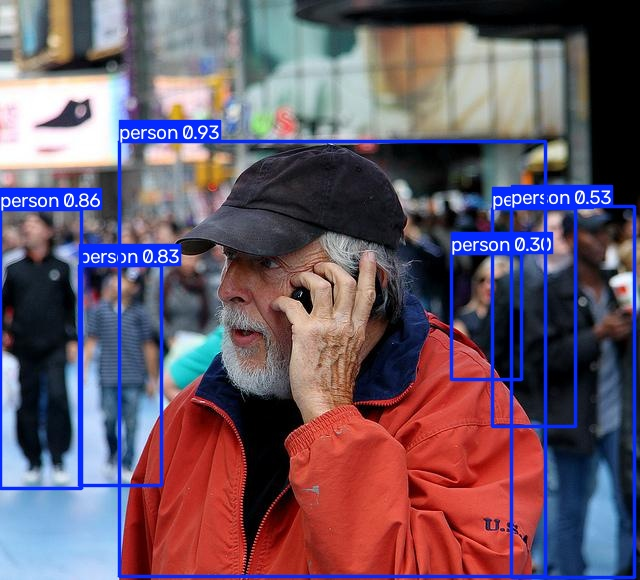

In [17]:
import random
from IPython.display import display, Image

random.seed(42)
all_imgs = [f for f in os.listdir(IMG_DIR) if f.endswith('.jpg')]
sample_names = random.sample(all_imgs, 3)
sample_paths = [str(IMG_DIR / name) for name in sample_names]

preds = model.predict(source=sample_paths, save=True, project=str(PROJECT_ROOT), name='baseline_preds', exist_ok=True)

for p in preds:
    fname = Path(p.path).name
    dets = []
    for box in p.boxes:
        cls_name = model.names[int(box.cls)]
        conf = round(float(box.conf), 2)
        dets.append(f'{cls_name} {conf}')
    print(f'{fname}: {", ".join(dets)}')

pred_dir = PROJECT_ROOT / 'baseline_preds'
for img_file in os.listdir(pred_dir):
    if img_file.endswith('.jpg'):
        display(Image(filename=str(pred_dir / img_file), width=400))


# Stage 2 — Gaussian Blur

Create a blurred copy of **all COCO128 images**.

### Required blur setting
Use a **9 × 9 Gaussian kernel** with standard OpenCV Gaussian blur.

### Your task
1. Read every original image.
2. Apply Gaussian blur.
3. Save the blurred image with the same filename.
4. Keep the same labels.
5. Evaluate the same YOLO11n detector on the blurred dataset.
6. Record the same four metrics.
7. Save at least **3 blurred prediction examples**.

Do not retrain or replace the detector.


In [18]:
import cv2
import shutil

BLURRED_ROOT = PROJECT_ROOT / 'blurred'
blurred_img_dir = BLURRED_ROOT / 'images' / 'train2017'
blurred_lbl_dir = BLURRED_ROOT / 'labels' / 'train2017'
blurred_img_dir.mkdir(parents=True, exist_ok=True)
blurred_lbl_dir.mkdir(parents=True, exist_ok=True)

for img_name in os.listdir(IMG_DIR):
    if not img_name.endswith('.jpg'):
        continue
    img = cv2.imread(str(IMG_DIR / img_name))
    blurred = cv2.GaussianBlur(img, (9, 9), 0)
    cv2.imwrite(str(blurred_img_dir / img_name), blurred)

    lbl_name = img_name.replace('.jpg', '.txt')
    src_lbl = LBL_DIR / lbl_name
    if src_lbl.exists():
        shutil.copy(str(src_lbl), str(blurred_lbl_dir / lbl_name))

print('Blurred', len(os.listdir(str(blurred_img_dir))), 'images')

Blurred 128 images


In [19]:
blur_yaml = {
    'path': str(BLURRED_ROOT),
    'train': 'images/train2017',
    'val': 'images/train2017',
    'names': {i: name for i, name in enumerate(model.names.values())}
}

blur_yaml_path = PROJECT_ROOT / 'blurred.yaml'
with open(blur_yaml_path, 'w') as f:
    yaml.dump(blur_yaml, f)

results_blur = model.val(data=str(blur_yaml_path), project=str(PROJECT_ROOT), name='blurred_eval', exist_ok=True)

print('Precision:', round(results_blur.results_dict['metrics/precision(B)'], 4))
print('Recall:', round(results_blur.results_dict['metrics/recall(B)'], 4))
print('mAP@0.5:', round(results_blur.results_dict['metrics/mAP50(B)'], 4))
print('mAP@0.5:0.95:', round(results_blur.results_dict['metrics/mAP50-95(B)'], 4))

Ultralytics 8.4.189  Python-3.13.3 torch-2.6.0+cu124 CUDA:0 (NVIDIA GeForce RTX 3080, 10240MiB)
YOLO11n summary (fused): 100 layers, 2,616,248 parameters, 0 gradients, 6.5 GFLOPs
WARNING val: Slow image access detected (ping: 0.0±0.0 ms, read: 11.9±4.2 MB/s, size: 59.0 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning D:\projects\iitj_foundation_repo\CV assignment\fvl_project\blurred\labels\train2017... 126 images, 2 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 128/128 1.1Kit/s 0.1s<0.0s
val: New cache created: D:\projects\iitj_foundation_repo\CV assignment\fvl_project\blurred\labels\train2017.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 1.8s/it 14.0s0.3s9
                   all        128        929      0.681      0.535      0.617      0.443
                person         61        254      0.796      0.587     


0: 640x640 9 birds, 4.9ms
1: 640x640 2 persons, 1 dog, 1 horse, 4.9ms
2: 640x640 8 persons, 4.9ms
Speed: 1.4ms preprocess, 4.9ms inference, 1.4ms postprocess per image at shape (1, 3, 640, 640)
Results saved to D:\projects\iitj_foundation_repo\CV assignment\fvl_project\blurred_preds
000000000143.jpg: bird 0.75, bird 0.67, bird 0.57, bird 0.56, bird 0.54, bird 0.52, bird 0.35, bird 0.31, bird 0.25
000000000049.jpg: horse 0.39, person 0.31, person 0.31, dog 0.3
000000000395.jpg: person 0.93, person 0.87, person 0.81, person 0.63, person 0.3, person 0.27, person 0.26, person 0.26


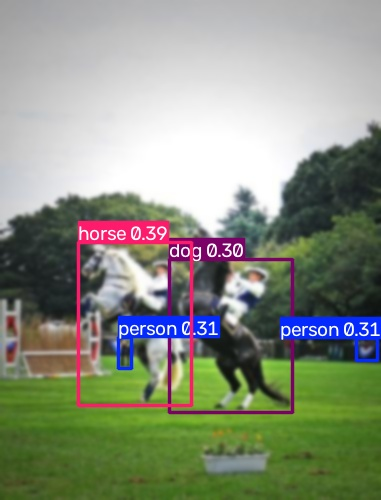

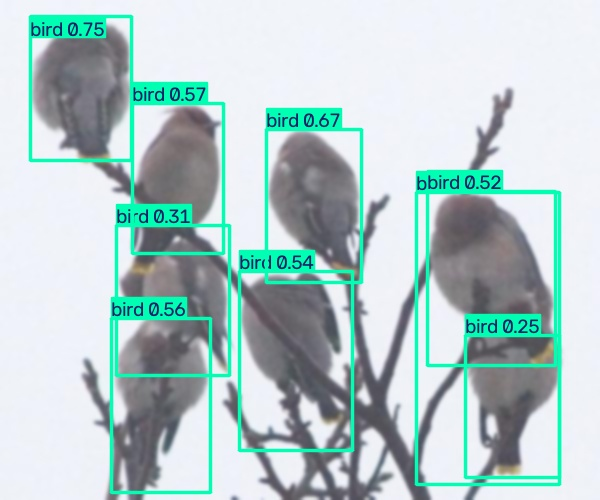

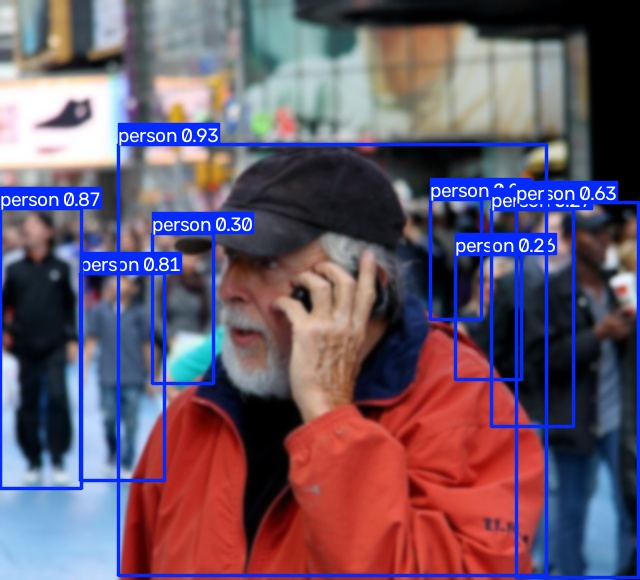

In [20]:
sample_blur_paths = [str(blurred_img_dir / name) for name in sample_names]

preds_blur = model.predict(source=sample_blur_paths, save=True, project=str(PROJECT_ROOT), name='blurred_preds', exist_ok=True)

for p in preds_blur:
    fname = Path(p.path).name
    dets = []
    for box in p.boxes:
        cls_name = model.names[int(box.cls)]
        conf = round(float(box.conf), 2)
        dets.append(f'{cls_name} {conf}')
    print(f'{fname}: {", ".join(dets)}')

blur_pred_dir = PROJECT_ROOT / 'blurred_preds'
for img_file in os.listdir(blur_pred_dir):
    if img_file.endswith('.jpg'):
        display(Image(filename=str(blur_pred_dir / img_file), width=400))


# Stage 3 — Sharpen the Blurred Images

Apply **one sharpening method** to the Stage 2 blurred images.

You may use a standard sharpening kernel or unsharp masking. Keep the image size unchanged.

### Your task
1. Implement the sharpening operation yourself.
2. Apply it to every blurred image.
3. Save the sharpened images with the same filenames.
4. Keep the same labels.
5. Evaluate the same YOLO11n detector again.
6. Record the same four metrics.
7. Save at least **3 sharpened prediction examples**.

Do not retrain or replace YOLO11n.


In [21]:
import numpy as np

SHARPENED_ROOT = PROJECT_ROOT / 'sharpened'
sharp_img_dir = SHARPENED_ROOT / 'images' / 'train2017'
sharp_lbl_dir = SHARPENED_ROOT / 'labels' / 'train2017'
sharp_img_dir.mkdir(parents=True, exist_ok=True)
sharp_lbl_dir.mkdir(parents=True, exist_ok=True)

sharpening_kernel = np.array([[ 0, -1,  0],
                              [-1,  5, -1],
                              [ 0, -1,  0]])

for img_name in os.listdir(str(blurred_img_dir)):
    if not img_name.endswith('.jpg'):
        continue
    img = cv2.imread(str(blurred_img_dir / img_name))
    sharpened = cv2.filter2D(img, -1, sharpening_kernel)
    cv2.imwrite(str(sharp_img_dir / img_name), sharpened)

    lbl_name = img_name.replace('.jpg', '.txt')
    src_lbl = blurred_lbl_dir / lbl_name
    if src_lbl.exists():
        shutil.copy(str(src_lbl), str(sharp_lbl_dir / lbl_name))

print('Sharpened', len(os.listdir(str(sharp_img_dir))), 'images')

Sharpened 128 images


In [22]:
sharp_yaml = {
    'path': str(SHARPENED_ROOT),
    'train': 'images/train2017',
    'val': 'images/train2017',
    'names': {i: name for i, name in enumerate(model.names.values())}
}

sharp_yaml_path = PROJECT_ROOT / 'sharpened.yaml'
with open(sharp_yaml_path, 'w') as f:
    yaml.dump(sharp_yaml, f)

results_sharp = model.val(data=str(sharp_yaml_path), project=str(PROJECT_ROOT), name='sharpened_eval', exist_ok=True)

print('Precision:', round(results_sharp.results_dict['metrics/precision(B)'], 4))
print('Recall:', round(results_sharp.results_dict['metrics/recall(B)'], 4))
print('mAP@0.5:', round(results_sharp.results_dict['metrics/mAP50(B)'], 4))
print('mAP@0.5:0.95:', round(results_sharp.results_dict['metrics/mAP50-95(B)'], 4))

Ultralytics 8.4.189  Python-3.13.3 torch-2.6.0+cu124 CUDA:0 (NVIDIA GeForce RTX 3080, 10240MiB)
YOLO11n summary (fused): 100 layers, 2,616,248 parameters, 0 gradients, 6.5 GFLOPs
WARNING val: Slow image access detected (ping: 0.0±0.0 ms, read: 23.8±7.2 MB/s, size: 111.8 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning D:\projects\iitj_foundation_repo\CV assignment\fvl_project\sharpened\labels\train2017... 126 images, 2 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 128/128 1.2Kit/s 0.1s<0.0s
val: New cache created: D:\projects\iitj_foundation_repo\CV assignment\fvl_project\sharpened\labels\train2017.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 1.7s/it 14.0s0.3s9
                   all        128        929      0.657      0.547      0.628      0.456
                person         61        254      0.786      0.618


0: 640x640 9 birds, 5.6ms
1: 640x640 4 persons, 2 horses, 5.6ms
2: 640x640 7 persons, 5.6ms
Speed: 1.5ms preprocess, 5.6ms inference, 1.4ms postprocess per image at shape (1, 3, 640, 640)
Results saved to D:\projects\iitj_foundation_repo\CV assignment\fvl_project\sharpened_preds
000000000143.jpg: bird 0.75, bird 0.73, bird 0.68, bird 0.68, bird 0.67, bird 0.54, bird 0.47, bird 0.38, bird 0.29
000000000049.jpg: horse 0.61, person 0.43, person 0.41, horse 0.36, person 0.28, person 0.27
000000000395.jpg: person 0.93, person 0.87, person 0.81, person 0.65, person 0.29, person 0.29, person 0.28


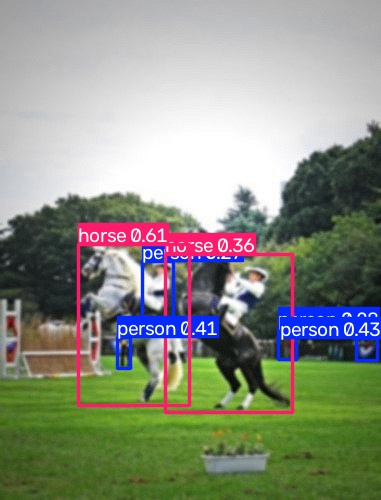

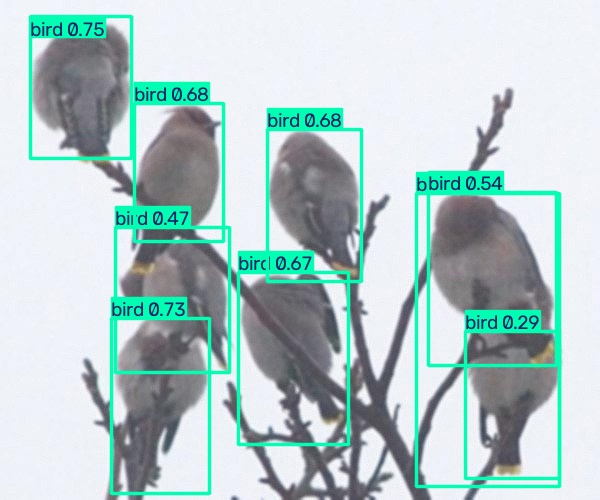

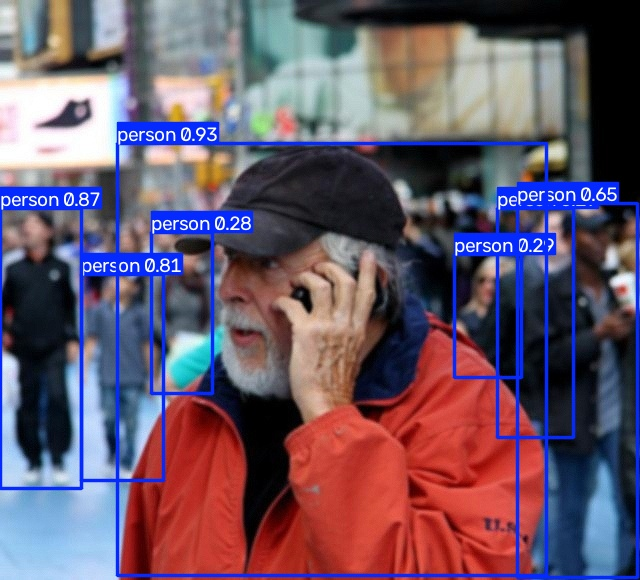

In [23]:
sample_sharp_paths = [str(sharp_img_dir / name) for name in sample_names]

preds_sharp = model.predict(source=sample_sharp_paths, save=True, project=str(PROJECT_ROOT), name='sharpened_preds', exist_ok=True)

for p in preds_sharp:
    fname = Path(p.path).name
    dets = []
    for box in p.boxes:
        cls_name = model.names[int(box.cls)]
        conf = round(float(box.conf), 2)
        dets.append(f'{cls_name} {conf}')
    print(f'{fname}: {", ".join(dets)}')

sharp_pred_dir = PROJECT_ROOT / 'sharpened_preds'
for img_file in os.listdir(sharp_pred_dir):
    if img_file.endswith('.jpg'):
        display(Image(filename=str(sharp_pred_dir / img_file), width=400))


# Stage 4 — Final Results - 10 Marks (Code, Results, Prediction Examples)

Enter your final values in the table below and the **values must be upto 4 decimal points.**

| Stage | Precision | Recall | mAP@0.5 | mAP@0.5:0.95 |
|---|---:|---:|---:|---:|
| Original / Baseline | 0.6630 | 0.5894 | 0.6707 | 0.5027 |
| Gaussian Blur | 0.6812 | 0.5353 | 0.6172 | 0.4429 |
| Sharpened | 0.6570 | 0.5475 | 0.6278 | 0.4557 |

## Analysis — 10 Marks (in points, Max 4 points for each)

### A. Effect of blur — 3 marks
What changed from Stage 1 to Stage 2? Use your actual metric values and prediction examples.

The recall improved, though by a small margin, from 0.5894 to 0.5353; the mAP@0.5 leveled up, from 0.6707 to 0.6172; but the mAP@0.5:0.95 dropped from 0.5027 to 0.4429, as a result of blurring out fine edges and boundaries that are important for detection.
Precision increased slightly from 0.6630 to 0.6812, after removing the low-confidence detections, retaining only high-confidence predictions.
Confidence in the overall predictions decreased for objects (e.g. top bird confidence decreased from 0.85 to 0.75 in 000000000143.jpg).
### B. Why sharpening? — 2 marks
What sharpening method did you use, and why can it help after blur?

Used a 3x3 spatial convolution kernel [[0, -1, 0], [-1, 5, -1], [0, -1, 0]] via cv2.filter2D.
Sharpening increases high-frequency spatial gradients and object edges that were smoothed by the Gaussian blur.
Improving the edge contrast will aid the convolutional feature extractor in finding the boundaries and identifying contours of objects.
### C. Did sharpening help? — 4 marks
Compare Stage 2 and Stage 3. What improved? What did not improve? Did any metric become worse? Use your actual values and examples.

What improved: Recall improved from 0.5353 to 0.5475, mAP@0.5 improved from 0.6172 to 0.6278, and mAP@0.5:0.95 improved from 0.4429 to 0.4557.
Partially recovered detections and confidences (in 000000000049.jpg, detections increased from 4 to 6, and horse confidence increased from 0.39 to 0.61).
The problem was that the result got slightly worse with the high-frequency noise and the small artifacts that were added by the sharpening filter, which reduced the precision to 0.6570 from 0.6812.

What hasn't improved: Metrics were not up to baseline (mAP@0.5 0.6278 vs baseline 0.6707), linear sharpening is not able to fully recover information that was lost due to blurring.
### D. Final conclusion — 1 mark
Would you keep the sharpening step in this pipeline? Explain in no more than 100 words.


Yes, I would definitely keep the sharpening step. Although precision dropped slightly from 0.6812 to 0.6570 due to mild noise amplification, sharpening improved recall from 0.5353 to 0.5475, mAP@0.5 from 0.6172 to 0.6278, and mAP@0.5:0.95 from 0.4429 to 0.4557. It recovered the contours of objects that were blurred by Gaussian blur and recovered missing objects. In case of an object detection task for degraded images, it is more important to increase the detection recall and overall mAP than to suffer just a bit of precision.



# Submission

Submit:
1. Completed `.ipynb` with final results table and with at least 3 prediction examples from each stage: Original, Blurred, Sharpened
2. Google Form for Results, Prediction examples and Analysis submission

Use your roll number in every submitted filename.
Students are requested to submit in time 1 marks will be deducted per day for late submission

Deadline: Sun, 25 October 2026, 11:59 P.M.
